# IPL 2022 — Exploratory Data Analysis

This notebook explores match-level data from the **IPL 2022 season** (74 matches, from the group stage through the final on May 29, 2022, played entirely across venues in Maharashtra, Gujarat, and West Bengal). Each row is one match, with the two teams, toss outcome, first/second innings scores and wickets, match result, player of the match, top scorer, and best bowling figures.

**Goals of this analysis:**
- Compare team performance by number of wins
- Examine toss decisions and how much they favor a particular strategy
- Look at scoring patterns (top scores, first vs. second innings, margins of victory)
- Identify which players and venues stood out most across the season
- Check whether scoring changed over the course of the season

In [1]:
# importing libraries 
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings 
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("IPL.csv")

In [3]:
df.head()

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,second_ings_score,second_ings_wkts,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure
0,1,"March 26,2022","Wankhede Stadium, Mumbai",Chennai,Kolkata,Group,Kolkata,Field,131,5,133,4,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20
1,2,"March 27,2022","Brabourne Stadium, Mumbai",Delhi,Mumbai,Group,Delhi,Field,177,5,179,6,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18
2,3,"March 27,2022","Dr DY Patil Sports Academy, Mumbai",Banglore,Punjab,Group,Punjab,Field,205,2,208,5,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59
3,4,"March 28,2022","Wankhede Stadium, Mumbai",Gujarat,Lucknow,Group,Gujarat,Field,158,6,161,5,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25
4,5,"March 29,2022","Maharashtra Cricket Association Stadium,Pune",Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,149,7,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   match_id             74 non-null     int64
 1   date                 74 non-null     str  
 2   venue                74 non-null     str  
 3   team1                74 non-null     str  
 4   team2                74 non-null     str  
 5   stage                74 non-null     str  
 6   toss_winner          74 non-null     str  
 7   toss_decision        74 non-null     str  
 8   first_ings_score     74 non-null     int64
 9   first_ings_wkts      74 non-null     int64
 10  second_ings_score    74 non-null     int64
 11  second_ings_wkts     74 non-null     int64
 12  match_winner         74 non-null     str  
 13  won_by               74 non-null     str  
 14  margin               74 non-null     int64
 15  player_of_the_match  74 non-null     str  
 16  top_scorer           74 non-null     st

In [5]:
df["date"] = df["date"].str.replace("April11,2022" , "April 11,2022" , regex = False)
df["date"] = pd.to_datetime(df["date"] , format = "%B %d,%Y")

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   match_id             74 non-null     int64         
 1   date                 74 non-null     datetime64[us]
 2   venue                74 non-null     str           
 3   team1                74 non-null     str           
 4   team2                74 non-null     str           
 5   stage                74 non-null     str           
 6   toss_winner          74 non-null     str           
 7   toss_decision        74 non-null     str           
 8   first_ings_score     74 non-null     int64         
 9   first_ings_wkts      74 non-null     int64         
 10  second_ings_score    74 non-null     int64         
 11  second_ings_wkts     74 non-null     int64         
 12  match_winner         74 non-null     str           
 13  won_by               74 non-null     str        

In [7]:
df.describe()

,match_id,date,first_ings_score,first_ings_wkts,second_ings_score,second_ings_wkts,margin,highscore
count,74.000000,74,74.000000,74.000000,74.000000,74.000000,74.000000,74.000000
mean,37.500000,2022-04-24 21:24:19.459459,171.121622,6.135135,158.540541,6.175676,16.972973,71.716216
min,1.000000,2022-03-26 00:00:00,68.000000,0.000000,72.000000,1.000000,2.000000,28.000000
25%,19.250000,2022-04-10 00:00:00,154.250000,5.000000,142.750000,4.000000,5.250000,57.000000
50%,37.500000,2022-04-24 12:00:00,169.500000,6.000000,160.000000,6.000000,8.000000,68.000000
75%,55.750000,2022-05-08 18:00:00,192.750000,8.000000,176.000000,8.000000,18.000000,87.750000
max,74.000000,2022-05-29 00:00:00,222.000000,10.000000,211.000000,10.000000,91.000000,140.000000
std,21.505813,NaN,29.048355,2.222699,29.299207,2.639832,19.651047,20.705052


In [8]:
df.isnull().sum()

match_id               0
date                   0
venue                  0
team1                  0
team2                  0
stage                  0
toss_winner            0
toss_decision          0
first_ings_score       0
first_ings_wkts        0
second_ings_score      0
second_ings_wkts       0
match_winner           0
won_by                 0
margin                 0
player_of_the_match    0
top_scorer             0
highscore              0
best_bowling           0
best_bowling_figure    0
dtype: int64

In [9]:
df["venue"].unique()

<StringArray>
[                    'Wankhede Stadium, Mumbai',
                    'Brabourne Stadium, Mumbai',
           'Dr DY Patil Sports Academy, Mumbai',
 'Maharashtra Cricket Association Stadium,Pune',
                        'Eden Gardens, Kolkata',
             'Narendra Modi Stadium, Ahmedabad']
Length: 6, dtype: str

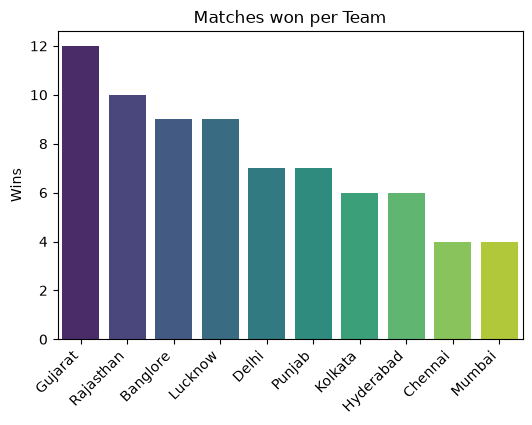

In [11]:
wins = df["match_winner"].value_counts()

plt.figure(figsize = (6,4))
sns.barplot(y = wins.values , x = wins.index , hue = wins.index , palette = "viridis")
plt.ylabel("Wins")
plt.xlabel("")
plt.xticks(rotation = 45 , ha = "right")
plt.title("Matches won per Team")
plt.show()

**Observation:** Gujarat led the season with 12 wins (fittingly, they also won the final against Rajasthan), followed by Rajasthan (10) and a tie between Bangalore and Lucknow (9 each). Mumbai and Chennai — two of the IPL's most historically successful franchises — finished at the bottom with only 4 wins each, marking a notably down season for both.

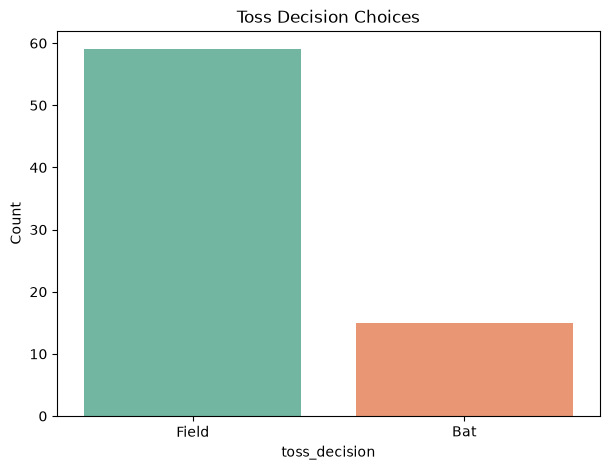

In [12]:
plt.figure(figsize = (7,5))
sns.countplot(data = df , x = "toss_decision" , hue = "toss_decision" , palette = "Set2")
plt.title("Toss Decision Choices")
plt.ylabel("Count")
plt.show()

**Observation:** Teams chose to field first in 59 of 74 matches (about 80%), compared to just 15 choosing to bat first. This heavily lopsided split suggests a strong perceived advantage to chasing in this season — likely tied to dew affecting evening matches and general T20 chasing strategy.

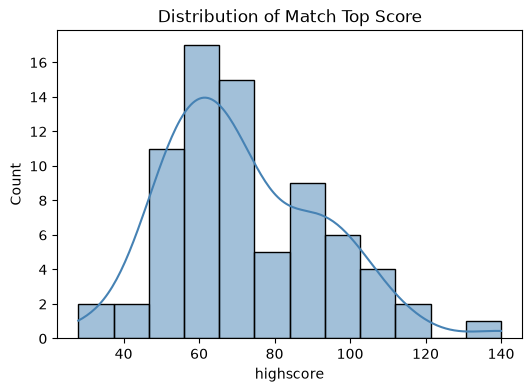

In [13]:
plt.figure(figsize = (6,4))
sns.histplot(df["highscore"] , bins = 12 , kde = True , color = "steelblue")
plt.title("Distribution of Match Top Score")
plt.show()

**Observation:** The highest individual score in a match ranges from 28 to 140, with a mean of about 72 and most matches falling between 57 and 88. The distribution has a mild right skew — a small number of standout individual innings (in the 100+ range) pull the tail upward, while the bulk of matches saw more modest top scores.

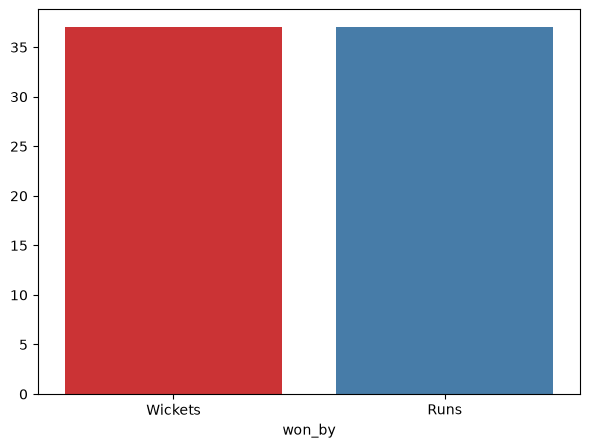

In [14]:
plt.figure(figsize = (7,5))
sns.countplot(x ="won_by" , hue = "won_by" , data = df , palette = "Set1")
plt.ylabel("")
plt.show()

**Observation:** Wins are split almost exactly evenly between winning by wickets (37) and winning by runs (37). However, the *margins* differ sharply: matches won by runs had an average margin of about 28 runs — often fairly decisive — while matches won by wickets averaged only 6 wickets, indicating closer, tighter finishes for chasing teams.

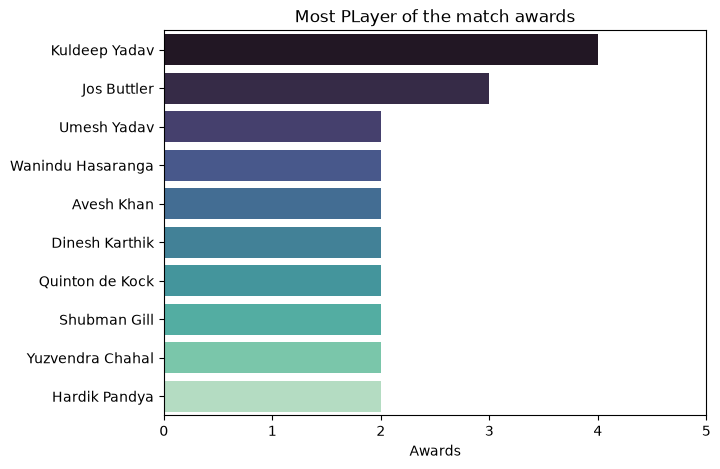

In [15]:
player = df["player_of_the_match"].value_counts().head(10)

plt.figure(figsize = (7,5))
sns.barplot(x = player.values , y = player.index , hue = player.index , palette = "mako")
plt.title("Most PLayer of the match awards")
plt.xlabel("Awards")
plt.ylabel("")
plt.xlim(0,5)
plt.show()

**Observation:** Player-of-the-match awards are spread fairly evenly across the season rather than dominated by one standout — Kuldeep Yadav leads with 4 awards, while the rest of the top 10 (including Jos Buttler, Hardik Pandya, and Shubman Gill) are clustered at 2–3 each. This suggests a season without one singularly dominant individual performer.

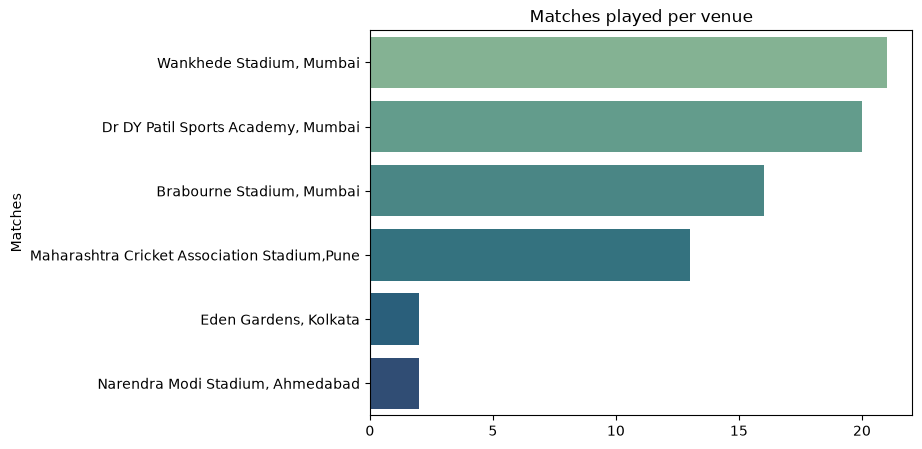

In [16]:
venues = df["venue"].value_counts()

plt.figure(figsize = (7,5))
sns.barplot(y = venues.index , x = venues.values , palette = "crest")
plt.title("Matches played per venue")
plt.xlabel("")
plt.ylabel("Matches")
plt.xticks(range(0,25,5))
plt.show()

**Observation:** Matches were heavily concentrated at just four Mumbai/Pune-area venues — Wankhede Stadium (21 matches), Dr DY Patil Sports Academy (20), Brabourne Stadium (16), and the Maharashtra Cricket Association Stadium in Pune (13) — together hosting 70 of 74 matches. Eden Gardens and Narendra Modi Stadium hosted only 2 matches each. This reflects the season's bio-bubble format, with nearly the entire tournament played in one region rather than teams' home cities.

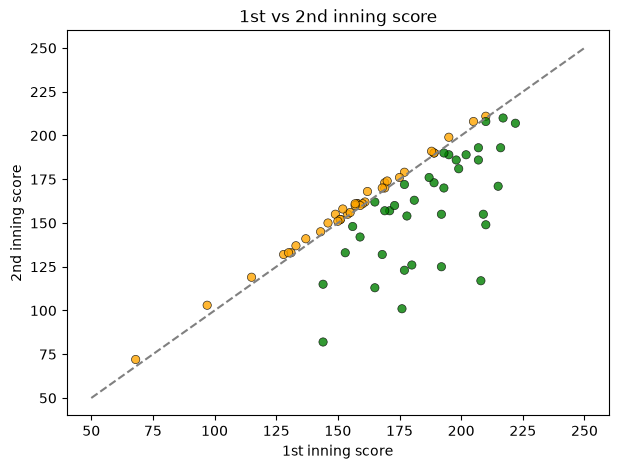

In [17]:
df["run_diff"] = df["first_ings_score"] - df["second_ings_score"]
colors = np.where(df["run_diff"] > 0 , "green" , "orange")

plt.figure(figsize = (7,5))
sns.scatterplot(data = df , x = "first_ings_score" , y = "second_ings_score" ,c = colors , alpha = 0.8 , edgecolor = "Black" )
plt.plot([50,250] , [50,250] , "--" , color = "gray")
plt.xlabel("1st inning score")
plt.ylabel("2nd inning score")
plt.title("1st vs 2nd inning score")
plt.show()

**Observation:** Teams batting first scored more on average (171 runs) than teams batting second (159 runs), and the majority of points sit above the dashed equality line, but the margin is often tight — only 37 of 74 matches saw the first innings actually surpass the second. Combined with the toss-decision chart above, this suggests batting first sets a somewhat higher total on average, but doesn't guarantee a win, since chasing sides still won half the matches in this season.

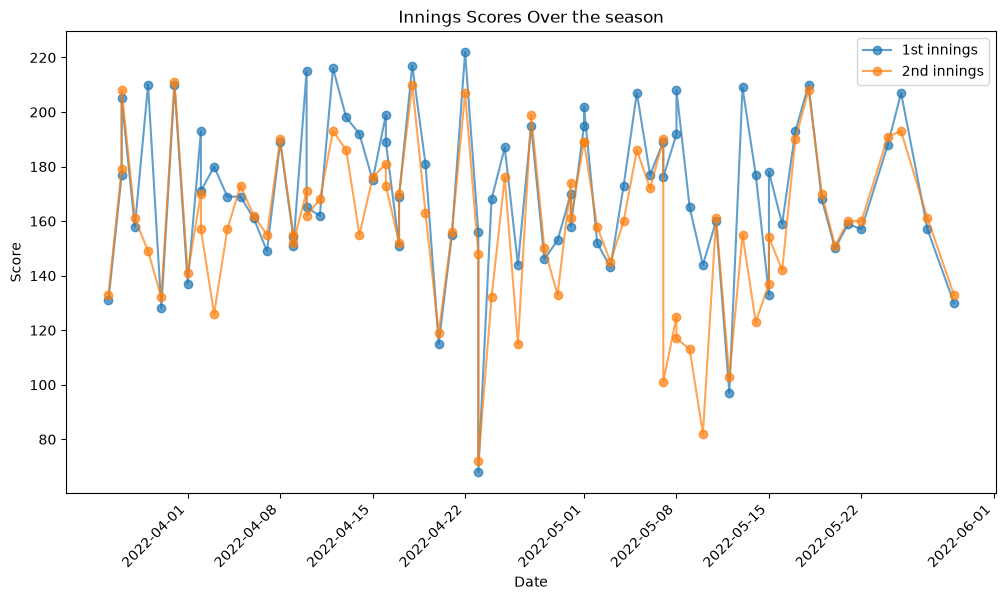

In [18]:
plt.figure(figsize = (12,6))
plt.plot(df["date"] , df["first_ings_score"] , marker = "o" , label = "1st innings" , alpha = 0.7)
plt.plot(df["date"] , df["second_ings_score"] , marker = "o" , label = "2nd innings" , alpha = 0.7)
plt.title("Innings Scores Over the season")
plt.xlabel("Date")
plt.ylabel("Score")
plt.xticks(rotation = 45 , ha = "right")
plt.legend()
plt.show()

**Observation:** Neither innings shows a meaningful trend over the course of the season — the correlation between date and score is close to zero for both first innings (-0.06) and second innings (-0.13). Scores fluctuate game to game without pitches getting noticeably higher- or lower-scoring as the tournament progressed.

## Conclusion

This analysis of the 74-match IPL 2022 season highlights a few clear patterns:

- **Gujarat had the standout season**, leading in wins (12) and going on to win the final against Rajasthan — while two traditionally strong franchises, Mumbai and Chennai, finished with the fewest wins (4 each).
- **Fielding first was the dominant strategy**, chosen in 80% of tosses, likely reflecting a perceived chasing advantage (e.g., dew in evening matches).
- **Batting first produced higher average scores** (171 vs. 159 runs), but this didn't translate into a guaranteed edge — chasing teams still won half the matches, and wins by wickets tended to be much closer (avg. margin of 6 wickets) than wins by runs (avg. margin of 28 runs).
- **No single player or venue dominated the season.** Player-of-the-match awards were spread across many players (top scorer: 4 awards), and while matches were concentrated at a handful of Mumbai/Pune venues due to the bio-bubble format, no one venue accounted for a majority of games.
- **Scoring stayed consistent across the season**, with no evidence that pitches got higher- or lower-scoring as the tournament progressed.

Overall, the 2022 season was competitive and fairly balanced — no dominant individual performer, a near-even split between run-based and wicket-based wins, and results driven more by team-level strategy (the toss/field-first pattern) than by any single standout factor.